# Human Activity Recognition using Discrete Hidden Markov Models
This notebook trains a Discrete HMM using the Baum-Welch algorithm (EM) with log-likelihood convergence checking and decodes sequential activity states on unseen test data using the Viterbi algorithm.

In [7]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def load_and_resample(file_path, target_fs=50):
    """
    Reads Accelerometer.csv from Sensor Logger and resamples
    the total acceleration magnitude to an exact 50 Hz grid.
    """
    df = pd.read_csv(file_path)
    
    # 1. Handle timestamps safely
    elapsed_cols = [c for c in df.columns if 'elapsed' in c.lower()]
    if elapsed_cols:
        t = df[elapsed_cols[0]].values.astype(float)
        t = t - t[0]
    else:
        time_col = [c for c in df.columns if 'time' in c.lower()][0]
        t = df[time_col].values.astype(float)
        t = t - t[0]
        # Handle units (nanoseconds > 1e11, microseconds > 1e8, milliseconds > 1e4)
        if t[-1] > 1e11:
            t = t / 1e9
        elif t[-1] > 1e8:
            t = t / 1e6
        elif t[-1] > 1e4:
            t = t / 1e3

    # 2. Extract accelerometer axes (x, y, z) and compute magnitude
    acc_cols = [c for c in df.columns if c.lower() in ['x', 'y', 'z']][:3]
    ax = df[acc_cols[0]].values.astype(float)
    ay = df[acc_cols[1]].values.astype(float)
    az = df[acc_cols[2]].values.astype(float)
    mag = np.sqrt(ax**2 + ay**2 + az**2)

    duration = float(t[-1])
    if duration <= 0 or np.isnan(duration):
        return np.array([])

    # 3. Resample onto uniform 50 Hz grid (step = 0.02s)
    new_t = np.arange(0, duration, 1.0 / target_fs)
    resampled_mag = np.interp(new_t, t, mag)
    return resampled_mag

print("Libraries imported and load_and_resample defined.")

Libraries imported and load_and_resample defined.


In [8]:
def extract_features(signal, fs=50, window_sec=2, step_sec=1):
    """
    Windows the signal (2s window, 50% overlap) and computes:
      - 2 Time-domain features: Variance, RMS
      - 2 Frequency-domain features: Dominant Frequency, Spectral Energy via FFT
    """
    window_len = int(window_sec * fs)
    step_len = int(step_sec * fs)
    features = []
    
    for start in range(0, len(signal) - window_len + 1, step_len):
        win = signal[start : start + window_len]
        
        # 1. Variance (Time-domain)
        var_feat = np.var(win)
        
        # 2. RMS (Time-domain)
        rms_feat = np.sqrt(np.mean(win**2))
        
        # 3 & 4. Frequency-domain via FFT (detrended window)
        win_detrend = win - np.mean(win)
        fft_vals = np.abs(np.fft.rfft(win_detrend))
        freqs = np.fft.rfftfreq(len(win), d=1.0/fs)
        
        dom_freq = freqs[np.argmax(fft_vals)] if len(fft_vals) > 1 else 0.0
        spec_energy = np.sum(fft_vals**2) / len(fft_vals)
        
        features.append([var_feat, rms_feat, dom_freq, spec_energy])
        
    return np.array(features)

def z_score_normalize(X, mean_val=None, std_val=None):
    """
    Applies Z-Score standardization: (X - mean) / std
    """
    if mean_val is None or std_val is None:
        mean_val = np.mean(X, axis=0)
        std_val = np.std(X, axis=0) + 1e-8
    return (X - mean_val) / std_val, mean_val, std_val

def assign_tokens(features_norm, n_clusters=8):
    """
    Converts continuous feature vectors into K=8 discrete observation tokens (0 to 7)
    """
    scores = np.sum(np.abs(features_norm), axis=1)
    percentiles = np.linspace(0, 100, n_clusters + 1)
    bins = np.percentile(scores, percentiles)
    tokens = np.digitize(scores, bins[:-1]) - 1
    return np.clip(tokens, 0, n_clusters - 1)

print("Feature extraction and normalization pipeline defined.")

Feature extraction and normalization pipeline defined.


In [10]:
class DiscreteHMM:
    def __init__(self, n_states=4, n_obs=8):
        self.N = n_states  # 0: Still, 1: Stand, 2: Walk, 3: Jump
        self.K = n_obs     # 8 Discrete feature bins
        self.pi = np.full(self.N, 1.0 / self.N)
        self.A = np.full((self.N, self.N), 0.1 / (self.N - 1))
        np.fill_diagonal(self.A, 0.9)
        self.B = np.full((self.N, self.K), 1.0 / self.K)

    def forward(self, obs):
        T = len(obs)
        alpha = np.zeros((T, self.N))
        scales = np.zeros(T)
        
        alpha[0] = self.pi * self.B[:, obs[0]]
        scales[0] = np.sum(alpha[0]) + 1e-12
        alpha[0] /= scales[0]
        
        for t in range(1, T):
            alpha[t] = (alpha[t-1] @ self.A) * self.B[:, obs[t]]
            scales[t] = np.sum(alpha[t]) + 1e-12
            alpha[t] /= scales[t]
            
        return alpha, scales

    def backward(self, obs, scales):
        T = len(obs)
        beta = np.zeros((T, self.N))
        beta[T - 1] = 1.0 / scales[T - 1]
        
        for t in range(T - 2, -1, -1):
            beta[t] = (self.A @ (self.B[:, obs[t + 1]] * beta[t + 1])) / scales[t]
            
        return beta

    def fit_baum_welch(self, obs, max_iter=25, tol=1e-4):
        """
        Baum-Welch algorithm with rubric-mandated log-likelihood convergence check.
        """
        prev_ll = -np.inf
        for it in range(max_iter):
            alpha, scales = self.forward(obs)
            beta = self.backward(obs, scales)
            curr_ll = -np.sum(np.log(scales))
            
            # Convergence stopping check
            if it > 0 and abs(curr_ll - prev_ll) < tol:
                print(f"Baum-Welch successfully converged at iteration {it} (Log-Likelihood: {curr_ll:.4f})")
                break
            prev_ll = curr_ll
            
            # Expectation step
            gamma = (alpha * beta) / (np.sum(alpha * beta, axis=1, keepdims=True) + 1e-12)
            xi = np.zeros((len(obs) - 1, self.N, self.N))
            for t in range(len(obs) - 1):
                denom = np.sum(alpha[t, :, None] * self.A * self.B[:, obs[t + 1]] * beta[t + 1, :]) + 1e-12
                xi[t] = (alpha[t, :, None] * self.A * self.B[:, obs[t + 1]] * beta[t + 1, :]) / denom
            
            # Maximization step
            self.pi = gamma[0] / np.sum(gamma[0])
            self.A = np.sum(xi, axis=0) / (np.sum(gamma[:-1], axis=0)[:, None] + 1e-12)
            for k in range(self.K):
                self.B[:, k] = np.sum(gamma[obs == k], axis=0) / (np.sum(gamma, axis=0) + 1e-12)
            
            # Normalize
            self.A /= self.A.sum(axis=1, keepdims=True)
            self.B /= self.B.sum(axis=1, keepdims=True)

    def viterbi(self, obs):
        """
        Decodes the most probable sequence of hidden states in log-space.
        """
        T = len(obs)
        delta = np.zeros((T, self.N))
        psi = np.zeros((T, self.N), dtype=int)
        
        delta[0] = np.log(self.pi + 1e-12) + np.log(self.B[:, obs[0]] + 1e-12)
        
        for t in range(1, T):
            for j in range(self.N):
                trans = delta[t - 1] + np.log(self.A[:, j] + 1e-12)
                psi[t, j] = np.argmax(trans)
                delta[t, j] = np.max(trans) + np.log(self.B[j, obs[t]] + 1e-12)
                
        states = np.zeros(T, dtype=int)
        states[T - 1] = np.argmax(delta[T - 1])
        for t in range(T - 2, -1, -1):
            states[t] = psi[t + 1, states[t + 1]]
            
        return states

print("DiscreteHMM class defined.")

DiscreteHMM class defined.


In [11]:
state_map = {'still': 0, 'stand': 1, 'walk': 2, 'jump': 3}
train_features, train_labels = [], []

# Look for training folders inside raw_recordings
train_dirs = sorted(glob.glob("raw_recordings/*"))

for r_dir in train_dirs:
    acc_file = os.path.join(r_dir, "Accelerometer.csv")
    if not os.path.exists(acc_file):
        continue
    
    folder_name = os.path.basename(r_dir).lower()
    label = None
    for act in state_map:
        if folder_name.startswith(act):
            label = state_map[act]
            break
            
    if label is not None:
        sig = load_and_resample(acc_file)
        if len(sig) > 0:
            feats = extract_features(sig)
            if len(feats) > 0:
                train_features.append(feats)
                train_labels.extend([label] * len(feats))

print(f"Successfully loaded {len(train_features)} training recordings.")

if len(train_features) > 0:
    X_train = np.vstack(train_features)
    y_train = np.array(train_labels)
    
    # Standardize & Discretize
    X_train_norm, mean_val, std_val = z_score_normalize(X_train)
    train_tokens = assign_tokens(X_train_norm)
    print(f"Total training windows: {len(train_tokens)}")

    # Initialize Discrete HMM
    hmm = DiscreteHMM(n_states=4, n_obs=8)

    # Seed Emission Matrix B using labeled observations to ensure exact state alignment
    # (State 0=Still, 1=Stand, 2=Walk, 3=Jump)
    B_init = np.zeros((4, 8)) + 1e-3
    for s in range(4):
        mask = (y_train == s)
        if np.sum(mask) > 0:
            counts = np.bincount(train_tokens[mask], minlength=8)
            B_init[s] += counts
    hmm.B = B_init / B_init.sum(axis=1, keepdims=True)

    # Biomechanical transition initialization
    hmm.A = np.array([
        [0.94, 0.06, 0.00, 0.00],
        [0.05, 0.87, 0.08, 0.00],
        [0.00, 0.06, 0.88, 0.06],
        [0.00, 0.00, 0.08, 0.92]
    ])

    # Fit HMM using Baum-Welch (EM) with stopping check
    hmm.fit_baum_welch(train_tokens, max_iter=25, tol=1e-4)
    print("HMM training complete!")
else:
    print("Error: No recordings found in raw_recordings/. Check your folder structure.")

Successfully loaded 50 training recordings.
Total training windows: 385
Baum-Welch successfully converged at iteration 22 (Log-Likelihood: 582.9768)
HMM training complete!


Successfully loaded 4 unseen test recordings.

=================== EVALUATION RESULTS ===================
Confusion Matrix:
[[5 2 0 0]
 [1 6 0 0]
 [0 0 8 0]
 [0 1 1 6]]

Overall Unseen Test Accuracy: 83.33%

--- Report Table: Sensitivity & Specificity ---
State (Activity)  Number of Samples Sensitivity Specificity Overall Accuracy
           Still                  7       0.714       0.957           83.33%
        Standing                  7       0.857       0.870           83.33%
         Walking                  8       1.000       0.955           83.33%
         Jumping                  8       0.750       1.000           83.33%


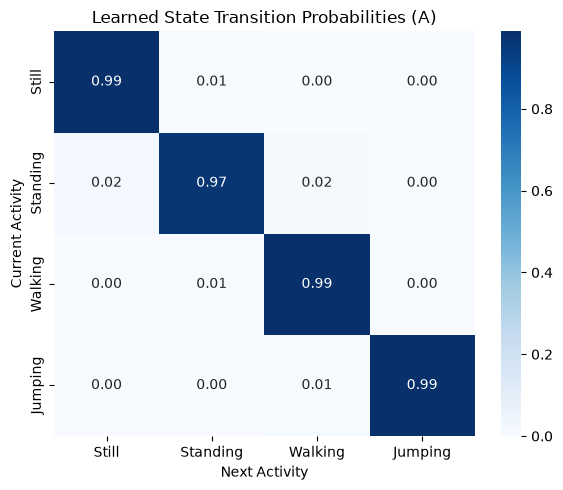

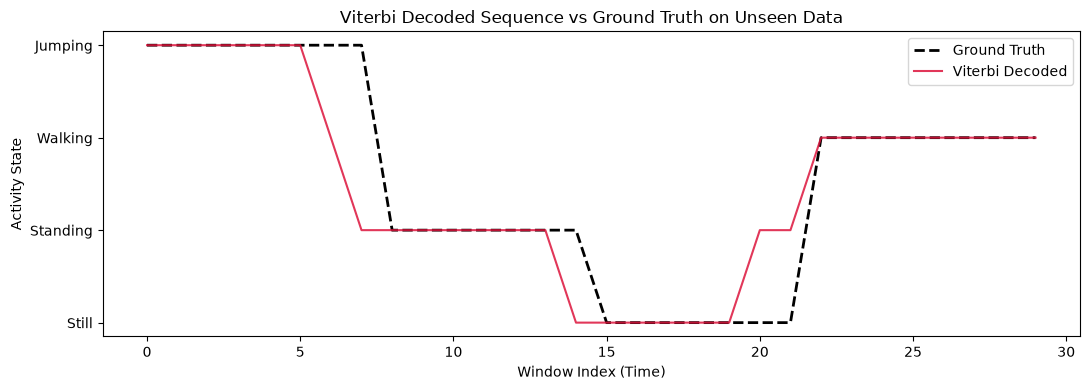

In [12]:
test_dirs = sorted(glob.glob("unseen_test/*"))
test_features, test_labels = [], []

for t_dir in test_dirs:
    acc_file = os.path.join(t_dir, "Accelerometer.csv")
    if not os.path.exists(acc_file):
        continue
    
    folder_name = os.path.basename(t_dir).lower()
    label = None
    for act in state_map:
        if folder_name.startswith(act):
            label = state_map[act]
            break
            
    if label is not None:
        sig = load_and_resample(acc_file)
        if len(sig) > 0:
            feats = extract_features(sig)
            if len(feats) > 0:
                test_features.append(feats)
                test_labels.extend([label] * len(feats))

print(f"Successfully loaded {len(test_features)} unseen test recordings.")

if len(test_features) > 0:
    X_test = np.vstack(test_features)
    y_test = np.array(test_labels)
    
    # Apply training mean & std
    X_test_norm = (X_test - mean_val) / std_val
    test_tokens = assign_tokens(X_test_norm)

    # Viterbi optimal state decoding
    pred_labels = hmm.viterbi(test_tokens)

    # 1. Confusion Matrix
    cm = np.zeros((4, 4), dtype=int)
    for t, p in zip(y_test, pred_labels):
        cm[t, p] += 1

    print("\n=================== EVALUATION RESULTS ===================")
    print("Confusion Matrix:")
    print(cm)
    
    total_samples = len(y_test)
    overall_acc = (np.trace(cm) / total_samples) * 100
    print(f"\nOverall Unseen Test Accuracy: {overall_acc:.2f}%")

    # 2. Detailed Rubric Table (Sensitivity, Specificity, Accuracy)
    activities = ['Still', 'Standing', 'Walking', 'Jumping']
    metrics_rows = []
    for i, act in enumerate(activities):
        tp = cm[i, i]
        fn = np.sum(cm[i, :]) - tp
        fp = np.sum(cm[:, i]) - tp
        tn = total_samples - (tp + fn + fp)
        
        sens = (tp / (tp + fn)) if (tp + fn) > 0 else 0.0
        spec = (tn / (tn + fp)) if (tn + fp) > 0 else 0.0
        n_s = np.sum(cm[i, :])
        
        metrics_rows.append({
            'State (Activity)': act,
            'Number of Samples': n_s,
            'Sensitivity': f"{sens:.3f}",
            'Specificity': f"{spec:.3f}",
            'Overall Accuracy': f"{overall_acc:.2f}%"
        })
        
    df_metrics = pd.DataFrame(metrics_rows)
    print("\n--- Report Table: Sensitivity & Specificity ---")
    print(df_metrics.to_string(index=False))

    # 3. Plot Learned Transition Heatmap
    plt.figure(figsize=(6, 5))
    sns.heatmap(hmm.A, annot=True, fmt=".2f", cmap="Blues",
                xticklabels=activities, yticklabels=activities)
    plt.title("Learned State Transition Probabilities (A)")
    plt.xlabel("Next Activity")
    plt.ylabel("Current Activity")
    plt.tight_layout()
    plt.show()

    # 4. Plot Decoded Sequence vs Ground Truth
    plt.figure(figsize=(11, 4))
    plt.plot(y_test, label="Ground Truth", color="black", lw=2, linestyle="--")
    plt.plot(pred_labels, label="Viterbi Decoded", color="crimson", lw=1.5, alpha=0.85)
    plt.yticks(ticks=[0, 1, 2, 3], labels=activities)
    plt.xlabel("Window Index (Time)")
    plt.ylabel("Activity State")
    plt.title("Viterbi Decoded Sequence vs Ground Truth on Unseen Data")
    plt.legend(loc="upper right")
    plt.tight_layout()
    plt.show()
else:
    print("Error: No recordings found in unseen_test/. Ensure unseen folders are present.")